# **KẾT NỐI GOOGLE DRIVE**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Exploratory Data Analysis (EDA)**

**Kiểm tra số lượng các cột dữ liệu**

In [3]:
import pandas as pd, numpy as np

df = pd.read_csv("/content/drive/MyDrive/IS6002/merged_dataset/combined_labeled_features_clean.csv", low_memory=False)
display(df.head())

,contract_id,PUSH1,MSTORE,CALLDATASIZE,LT,PUSH2,JUMPI,CALLDATALOAD,PUSH29,SWAP1,...,UNKNOWN_0xB5,UNKNOWN_0xD1,UNKNOWN_0xEC,UNKNOWN_0xA9,UNKNOWN_0xAC,UNKNOWN_0x2D,UNKNOWN_0xCA,label,vulnerability_type,source_dataset
0,C000001,470,109,22.0,13.0,170.0,89.0,32.0,1.0,258.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI
1,C000002,366,83,13.0,12.0,142.0,67.0,16.0,1.0,199.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI
2,C000003,1081,218,45.0,62.0,455.0,243.0,64.0,0.0,571.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI
3,C000004,1164,251,52.0,21.0,479.0,250.0,67.0,7.0,611.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI
4,C000005,556,131,22.0,34.0,193.0,96.0,34.0,0.0,279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable,Overflow-Underflow,SolidiFI


In [4]:
print("Số lượng cột:", len(df.columns))

print("\nDanh sách tên cột:")
for i, col in enumerate(df.columns):
    print(f"{i}: {col}")

Số lượng cột: 260

Danh sách tên cột:
0: contract_id
1: PUSH1
2: MSTORE
3: CALLDATASIZE
4: LT
5: PUSH2
6: JUMPI
7: CALLDATALOAD
8: PUSH29
9: SWAP1
10: DIV
11: PUSH4
12: AND
13: DUP1
14: EQ
15: JUMPDEST
16: REVERT
17: CALLVALUE
18: ISZERO
19: POP
20: JUMP
21: MLOAD
22: ADD
23: DUP3
24: DUP2
25: SUB
26: DUP4
27: SWAP2
28: DUP5
29: EXP
30: NOT
31: SWAP3
32: RETURN
33: PUSH20
34: STOP
35: SLOAD
36: MUL
37: KECCAK256
38: GT
39: CALLER
40: DUP6
41: SSTORE
42: PUSH32
43: LOG3
44: DUP7
45: DUP8
46: SWAP4
47: TIMESTAMP
48: DUP9
49: CALL
50: RETURNDATASIZE
51: RETURNDATACOPY
52: CALLDATACOPY
53: SWAP5
54: INVALID
55: OR
56: LOG1
57: SHR
58: PUSH5
59: ADDRESS
60: SHL
61: SWAP6
62: EXTCODESIZE
63: GAS
64: DUP10
65: LOG2
66: DUP11
67: PUSH8
68: SELFBALANCE
69: STATICCALL
70: NUMBER
71: MOD
72: BLOCKHASH
73: SELFDESTRUCT
74: SWAP8
75: CODECOPY
76: PUSH31
77: PUSH16
78: PUSH15
79: PUSH21
80: PUSH6
81: PUSH9
82: DUP13
83: DUP12
84: SWAP12
85: DUP14
86: DUP15
87: SWAP7
88: PUSH3
89: MSTORE8
90: SWAP11


In [5]:
print("Kích thước dataset:", df.shape)

print("\nSố contract:", len(df))
print("Số contract_id duy nhất:", df["contract_id"].nunique())

print("\nPhân bố label:")
print(df["label"].value_counts())

print("\nPhân bố source_dataset:")
print(df["source_dataset"].value_counts())


Kích thước dataset: (39905, 260)

Số contract: 39905
Số contract_id duy nhất: 39905

Phân bố label:
label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64

Phân bố source_dataset:
source_dataset
Slither-Wild         39414
SolidiFI               350
SmartBugs-Curated      141
Name: count, dtype: int64


**Phân bổ nhãn**

label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64

Tỷ lệ phần trăm:
label
Vulnerable        70.29
Non-vulnerable    29.71
Name: proportion, dtype: float64


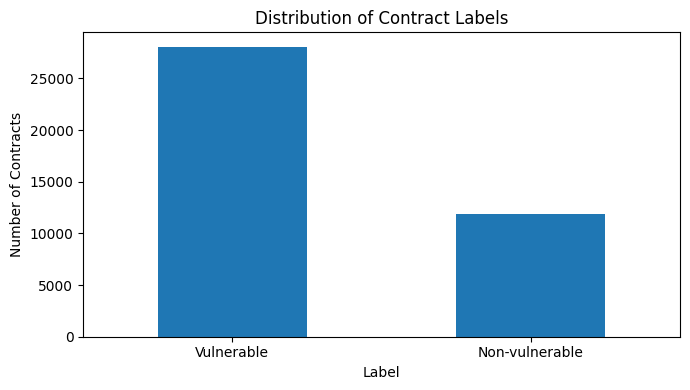

In [6]:
import matplotlib.pyplot as plt

label_counts = df["label"].value_counts()

print(label_counts)
print("\nTỷ lệ phần trăm:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

label_counts.plot(
    kind="bar",
    figsize=(7, 4),
    rot=0
)

plt.title("Distribution of Contract Labels")
plt.xlabel("Label")
plt.ylabel("Number of Contracts")
plt.tight_layout()
plt.show()


**Loại bỏ 2 cột "vulnerability_type" và "source_dataset"**

In [7]:
df = df.drop(columns=["vulnerability_type", "source_dataset"])

df.head()

,contract_id,PUSH1,MSTORE,CALLDATASIZE,LT,PUSH2,JUMPI,CALLDATALOAD,PUSH29,SWAP1,...,UNKNOWN_0xBE,UNKNOWN_0x28,UNKNOWN_0xB5,UNKNOWN_0xD1,UNKNOWN_0xEC,UNKNOWN_0xA9,UNKNOWN_0xAC,UNKNOWN_0x2D,UNKNOWN_0xCA,label
0,C000001,470,109,22.0,13.0,170.0,89.0,32.0,1.0,258.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
1,C000002,366,83,13.0,12.0,142.0,67.0,16.0,1.0,199.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
2,C000003,1081,218,45.0,62.0,455.0,243.0,64.0,0.0,571.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
3,C000004,1164,251,52.0,21.0,479.0,250.0,67.0,7.0,611.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
4,C000005,556,131,22.0,34.0,193.0,96.0,34.0,0.0,279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable


**Kiểm tra còn ô nào không có giá trị (là NaN/NULL không)**

In [8]:
print("Tổng NaN:", df.isna().sum().sum())

na_cols = df.isna().sum()
print(na_cols[na_cols > 0])

assert not df.isna().any().any(), "Vẫn còn NaN!"
print("Không có NaN/Null. Shape:", df.shape)

Tổng NaN: 0
Series([], dtype: int64)
Không có NaN/Null. Shape: (39905, 258)


In [9]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
contract_id,39905,39905,C035665,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PUSH1,39905.0,NaN,NaN,NaN,842.178699,940.470009,2.0,342.0,534.0,1000.0,18975.0
MSTORE,39905.0,NaN,NaN,NaN,201.968826,222.356865,1.0,84.0,131.0,236.0,3905.0
CALLDATASIZE,39905.0,NaN,NaN,NaN,20.463175,23.534432,0.0,6.0,15.0,25.0,460.0
LT,39905.0,NaN,NaN,NaN,23.874276,36.37846,0.0,9.0,13.0,24.0,1066.0
...,...,...,...,...,...,...,...,...,...,...,...
UNKNOWN_0xA9,39905.0,NaN,NaN,NaN,0.002757,0.220475,0.0,0.0,0.0,0.0,43.0
UNKNOWN_0xAC,39905.0,NaN,NaN,NaN,0.003659,0.398016,0.0,0.0,0.0,0.0,79.0
UNKNOWN_0x2D,39905.0,NaN,NaN,NaN,0.003258,0.0828,0.0,0.0,0.0,0.0,8.0
UNKNOWN_0xCA,39905.0,NaN,NaN,NaN,0.001353,0.039394,0.0,0.0,0.0,0.0,2.0


**Số lượng cột theo từng kiểu dữ liệu**

In [10]:
print("Số lượng cột theo kiểu dữ liệu:")
print(df.dtypes.value_counts())

Số lượng cột theo kiểu dữ liệu:
float64    254
object       2
int64        2
Name: count, dtype: int64


**Kiểm tra sự phân phối của các cột Opcode**

Số cột opcode: 256
Số giá trị thiếu trong opcode: 0

20 opcode xuất hiện nhiều nhất:


,total_count
PUSH1,33607141.0
SWAP1,18396075.0
POP,16793736.0
DUP1,16326735.0
PUSH2,13278148.0
DUP2,12945179.0
ADD,12264083.0
JUMPDEST,10689861.0
AND,10442519.0
ISZERO,8474033.0


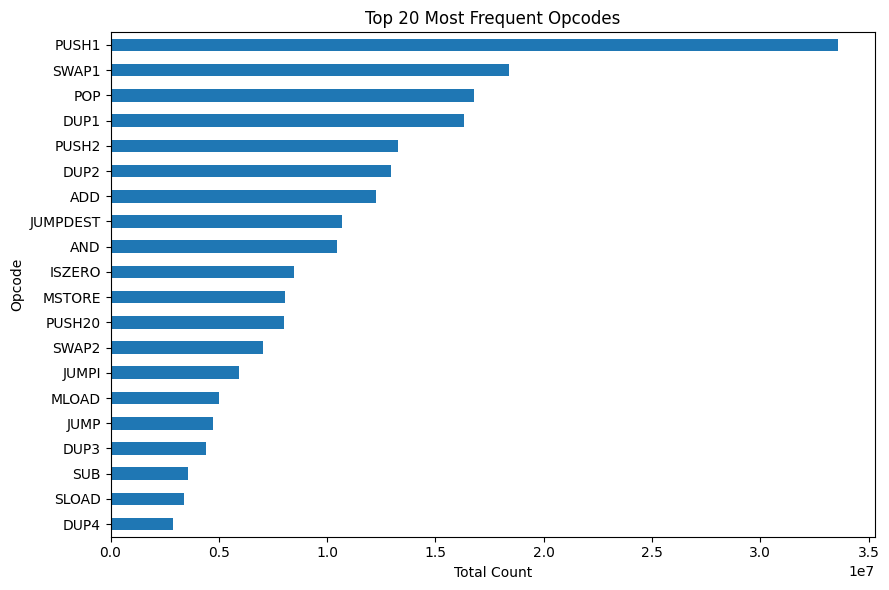

In [11]:
metadata_cols = [
    "contract_id",
    "label",
    "vulnerability_type",
    "source_dataset"
]

opcode_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

X_eda = df[opcode_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

print("Số cột opcode:", len(opcode_cols))
print("Số giá trị thiếu trong opcode:",
      X_eda.isnull().sum().sum())

opcode_totals = X_eda.sum().sort_values(ascending=False)

print("\n20 opcode xuất hiện nhiều nhất:")
display(opcode_totals.head(20).to_frame("total_count"))

opcode_totals.head(20).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 20 Most Frequent Opcodes")
plt.xlabel("Total Count")
plt.ylabel("Opcode")
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
Non-vulnerable,11857.0,3873.38,3033.61,6.0,2010.00,3325.0,4332.00,31638.0
Vulnerable,28048.0,6976.52,7679.08,21.0,2849.75,4633.0,8444.25,148591.0


<Figure size 900x500 with 0 Axes>

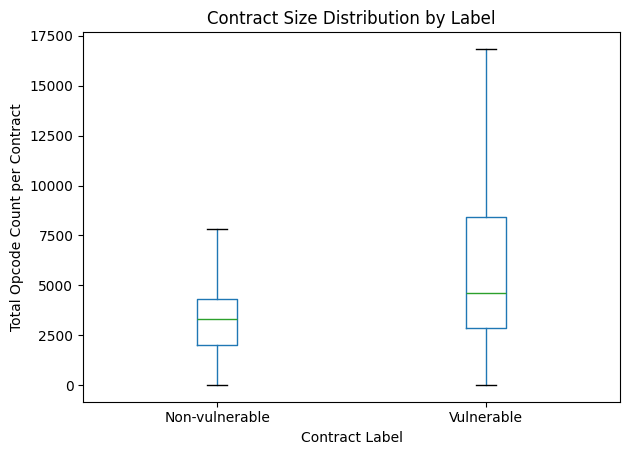

In [12]:
contract_size = X_eda.sum(axis=1)

plot_df = pd.DataFrame({
    "Contract Size": contract_size,
    "Label": df["label"].astype(str).str.strip()
})

display(
    plot_df.groupby("Label")["Contract Size"]
    .describe()
    .round(2)
)

plt.figure(figsize=(9, 5))

plot_df.boxplot(
    column="Contract Size",
    by="Label",
    grid=False,
    showfliers=False
)

plt.title("Contract Size Distribution by Label")
plt.suptitle("")
plt.xlabel("Contract Label")
plt.ylabel("Total Opcode Count per Contract")
plt.tight_layout()
plt.show()


# **PREPROCESSING**

In [13]:
df.head()

,contract_id,PUSH1,MSTORE,CALLDATASIZE,LT,PUSH2,JUMPI,CALLDATALOAD,PUSH29,SWAP1,...,UNKNOWN_0xBE,UNKNOWN_0x28,UNKNOWN_0xB5,UNKNOWN_0xD1,UNKNOWN_0xEC,UNKNOWN_0xA9,UNKNOWN_0xAC,UNKNOWN_0x2D,UNKNOWN_0xCA,label
0,C000001,470,109,22.0,13.0,170.0,89.0,32.0,1.0,258.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
1,C000002,366,83,13.0,12.0,142.0,67.0,16.0,1.0,199.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
2,C000003,1081,218,45.0,62.0,455.0,243.0,64.0,0.0,571.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
3,C000004,1164,251,52.0,21.0,479.0,250.0,67.0,7.0,611.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable
4,C000005,556,131,22.0,34.0,193.0,96.0,34.0,0.0,279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Vulnerable


In [14]:
y = df["label"].copy()

contract_ids = df["contract_id"].copy()

opcode_cols = [
    col for col in df.columns
    if col not in ["contract_id", "label"]
]

X = df[opcode_cols].copy()

print("Số contracts:", len(df))
print("Số opcode features:", len(opcode_cols))
print("Kích thước X:", X.shape)
print("\nPhân bố nhãn:")
print(y.value_counts())

Số contracts: 39905
Số opcode features: 256
Kích thước X: (39905, 256)

Phân bố nhãn:
label
Vulnerable        28048
Non-vulnerable    11857
Name: count, dtype: int64


In [15]:
print("Các kiểu dữ liệu trong X:")
print(X.dtypes.value_counts())

print("\nSố giá trị thiếu:", X.isna().sum().sum())
print("Số giá trị vô cực:", np.isinf(X.select_dtypes(include="number")).sum().sum())

Các kiểu dữ liệu trong X:
float64    254
int64        2
Name: count, dtype: int64

Số giá trị thiếu: 0
Số giá trị vô cực: 0


In [16]:
unique_counts = X.nunique()

constant_cols = unique_counts[unique_counts <= 1].index.tolist()

print("Số opcode features ban đầu:", X.shape[1])
print("Số constant features:", len(constant_cols))
print("\nDanh sách constant features:")
print(constant_cols)

Số opcode features ban đầu: 256
Số constant features: 0

Danh sách constant features:
[]


**Kiểm tra phân bố và độ lệch của dữ liệu X**

In [17]:
display(X.describe().T[["mean", "std", "min", "50%", "max"]].round(2))

,mean,std,min,50%,max
PUSH1,842.18,940.47,2.0,534.0,18975.0
MSTORE,201.97,222.36,1.0,131.0,3905.0
CALLDATASIZE,20.46,23.53,0.0,15.0,460.0
LT,23.87,36.38,0.0,13.0,1066.0
PUSH2,332.74,394.52,0.0,202.0,8955.0
...,...,...,...,...,...
UNKNOWN_0xEC,0.02,4.11,0.0,0.0,820.0
UNKNOWN_0xA9,0.00,0.22,0.0,0.0,43.0
UNKNOWN_0xAC,0.00,0.40,0.0,0.0,79.0
UNKNOWN_0x2D,0.00,0.08,0.0,0.0,8.0


# **AUTOENCODER**

Hướng tiếp cận của bài báo: huấn luyện autoencoder **chỉ trên dữ liệu non-harmful (Non-vulnerable)** để học biểu diễn "bình thường". Contract nào có **reconstruction error** vượt ngưỡng sẽ bị coi là bất thường (harmful/Vulnerable). Ngưỡng được chọn từ đường cong Precision–Recall.

**Import thư viện & cố định seed**

In [18]:
import time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (balanced_accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


**Mã hóa nhãn & chia Train/Test**

Quy ước: `1 = Vulnerable (harmful, lớp dương)`, `0 = Non-vulnerable (non-harmful, lớp "bình thường")`. Chia 80/20, có `stratify` để giữ tỉ lệ nhãn.

In [19]:
y_bin = (y.astype(str).str.strip() == "Vulnerable").astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X.values.astype("float64"), y_bin,
    test_size=0.2, stratify=y_bin, random_state=SEED
)

print("Train:", X_train.shape, "| Vulnerable:", y_train.sum(), "| Non-vulnerable:", (y_train == 0).sum())
print("Test :", X_test.shape,  "| Vulnerable:", y_test.sum(),  "| Non-vulnerable:", (y_test == 0).sum())

Train: (31924, 256) | Vulnerable: 22438 | Non-vulnerable: 9486
Test : (7981, 256) | Vulnerable: 5610 | Non-vulnerable: 2371


**Chuẩn hóa dữ liệu**

Số lượng opcode lệch phải rất mạnh (VD `PUSH1` max = 18975, nhiều `UNKNOWN_*` gần như bằng 0), nên áp dụng `log1p` rồi `MinMaxScaler` về [0, 1]. Lớp output dùng `sigmoid` nên cần dữ liệu nằm trong [0, 1] như bài báo mô tả. Scaler chỉ `fit` trên tập train để tránh rò rỉ dữ liệu.

In [20]:
scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(np.log1p(X_train)).astype("float32")
X_test_s  = scaler.transform(np.log1p(X_test)).astype("float32")

X_test_s = np.clip(X_test_s, 0.0, 1.0)

print("Min/Max train:", X_train_s.min(), X_train_s.max())

Min/Max train: 0.0 1.0


**Tập huấn luyện của autoencoder: chỉ dữ liệu Non-vulnerable**

Tách thêm 10% làm validation (cũng chỉ gồm Non-vulnerable) để theo dõi loss.

In [21]:
X_train_normal = X_train_s[y_train == 0]
X_fit, X_val = train_test_split(X_train_normal, test_size=0.1, random_state=SEED)

print("Autoencoder fit:", X_fit.shape, "| validation:", X_val.shape)

Autoencoder fit: (8537, 256) | validation: (949, 256)


**Xây dựng mô hình Autoencoder**

Theo bài báo: Encoder → Bottleneck → Decoder, hidden layer dùng `tanh` (giá trị trong [-1, 1]), output layer dùng `sigmoid` (giá trị trong [0, 1]), loss là bình phương sai số tái tạo (MSE).

In [22]:
input_dim = X_fit.shape[1]

inp = keras.Input(shape=(input_dim,), name="input")
# Encoder
x = layers.Dense(128, activation="tanh", name="enc_1")(inp)
x = layers.Dense(64,  activation="tanh", name="enc_2")(x)
# Bottleneck
z = layers.Dense(32,  activation="tanh", name="bottleneck")(x)
# Decoder
x = layers.Dense(64,  activation="tanh", name="dec_1")(z)
x = layers.Dense(128, activation="tanh", name="dec_2")(x)
out = layers.Dense(input_dim, activation="sigmoid", name="output")(x)

autoencoder = keras.Model(inp, out, name="autoencoder")
autoencoder.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_1 (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_2 (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_2 (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 256)            │        33,024 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 86,688 (338.62 KB)

 Trainable params: 86,688 (338.62 KB)

 Non-trainable params: 0 (0.00 B)

**Huấn luyện (20 epochs, batch size 2048 — đúng cấu hình bài báo)**

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - loss: 0.1980 - val_loss: 0.1718
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.1545 - val_loss: 0.1141
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0958 - val_loss: 0.0601
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0479 - val_loss: 0.0270
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0214 - val_loss: 0.0124
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0103 - val_loss: 0.0070
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0063 - val_loss: 0.0050
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0048 - val_loss: 0.0042
Epoch 9/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0042 - val_loss: 0.0038
Epoch 10/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0039 - val_loss: 0.0036
Epoch 11/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0037 - val_loss: 0.0035
Epoch 12/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0036 - val_loss: 0.0034
Ep

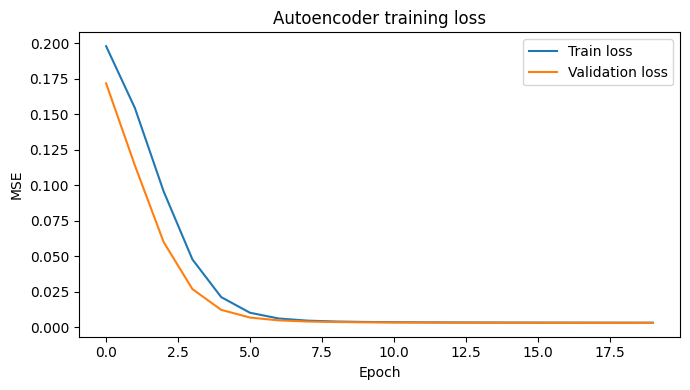

In [23]:
EPOCHS, BATCH = 20, 2048

t0 = time.time()
history = autoencoder.fit(
    X_fit, X_fit,
    epochs=EPOCHS, batch_size=BATCH,
    validation_data=(X_val, X_val),
    shuffle=True, verbose=1
)
train_time = time.time() - t0
print(f"\nThời gian huấn luyện: {train_time:.2f}s")

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Autoencoder training loss")
plt.legend(); plt.tight_layout(); plt.show()

**Reconstruction error của từng contract**

Reconstruction error = MSE giữa input và output trên từng mẫu. Đây là "anomaly score": càng lớn càng có khả năng là Vulnerable.

,count,mean,std,min,25%,50%,75%,max
Train - Non-vulnerable,9486.0,0.003323,0.003673,0.000524,0.001360,0.001893,0.003940,0.044749
Train - Vulnerable,22438.0,0.010995,0.012882,0.000587,0.003153,0.006711,0.013268,0.180463
Test - Non-vulnerable,2371.0,0.003362,0.005174,0.000524,0.001359,0.001908,0.003783,0.179936
Test - Vulnerable,5610.0,0.010655,0.012578,0.000521,0.003136,0.006551,0.012954,0.182308


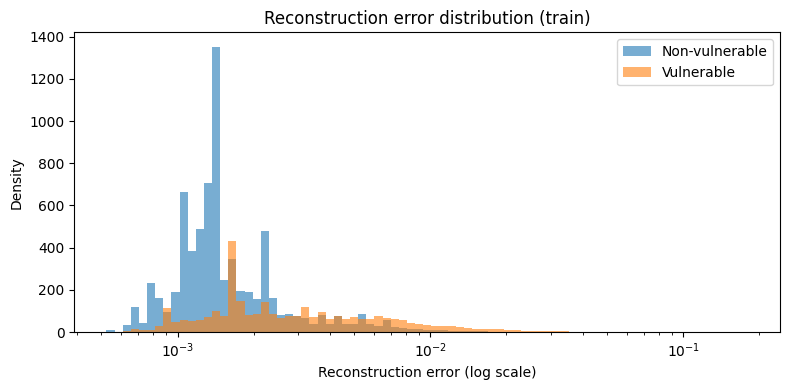

In [24]:
def recon_error(model, data, batch_size=4096):
    recon = model.predict(data, batch_size=batch_size, verbose=0)
    return np.mean(np.square(data - recon), axis=1)

t0 = time.time()
err_train = recon_error(autoencoder, X_train_s)
train_score_time = time.time() - t0

t0 = time.time()
err_test = recon_error(autoencoder, X_test_s)
test_score_time = time.time() - t0

summary = pd.DataFrame({
    "Train - Non-vulnerable": pd.Series(err_train[y_train == 0]).describe(),
    "Train - Vulnerable":     pd.Series(err_train[y_train == 1]).describe(),
    "Test - Non-vulnerable":  pd.Series(err_test[y_test == 0]).describe(),
    "Test - Vulnerable":      pd.Series(err_test[y_test == 1]).describe(),
}).T
display(summary)

plt.figure(figsize=(8, 4))
bins = np.logspace(np.log10(max(err_train.min(), 1e-8)), np.log10(err_train.max()), 80)
plt.hist(err_train[y_train == 0], bins=bins, alpha=0.6, label="Non-vulnerable", density=True)
plt.hist(err_train[y_train == 1], bins=bins, alpha=0.6, label="Vulnerable", density=True)
plt.xscale("log"); plt.xlabel("Reconstruction error (log scale)"); plt.ylabel("Density")
plt.title("Reconstruction error distribution (train)"); plt.legend(); plt.tight_layout(); plt.show()

**Chọn ngưỡng (threshold) từ đường cong Precision–Recall**

Bài báo chọn ngưỡng theo mục tiêu bài toán (Fig 8). Ở đây ngưỡng được chọn **trên tập train** (không dùng test) theo điểm có F1 của lớp Vulnerable cao nhất. Nếu muốn ưu tiên recall cao hơn (bỏ sót contract lỗi là tốn kém hơn), có thể đổi `THRESHOLD_MODE` sang `"recall"`.

> Lưu ý: ngưỡng "slightly under 4" trong bài báo phụ thuộc vào cách scale dữ liệu của họ, nên không dùng lại con số đó; ngưỡng ở đây được suy ra từ dữ liệu của nhóm.

Threshold = 0.001708  (precision=0.8051, recall=0.9364)


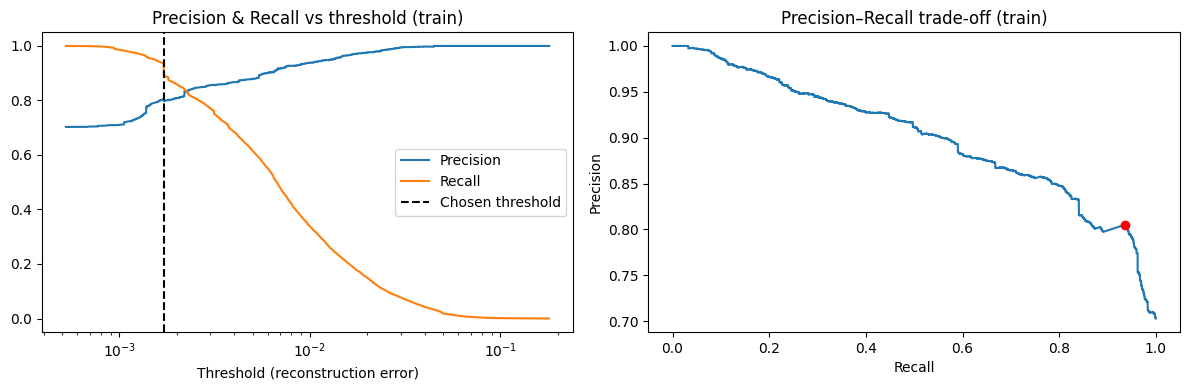

In [25]:
THRESHOLD_MODE = "f1"
TARGET_RECALL  = 0.80

prec, rec, thr = precision_recall_curve(y_train, err_train)
prec, rec = prec[:-1], rec[:-1]

if THRESHOLD_MODE == "f1":
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    idx = np.argmax(f1)
else:
    ok = np.where(rec >= TARGET_RECALL)[0]
    idx = ok[np.argmax(prec[ok])]

threshold = thr[idx]
print(f"Threshold = {threshold:.6f}  (precision={prec[idx]:.4f}, recall={rec[idx]:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(thr, prec, label="Precision"); ax[0].plot(thr, rec, label="Recall")
ax[0].axvline(threshold, color="k", ls="--", label="Chosen threshold")
ax[0].set_xscale("log"); ax[0].set_xlabel("Threshold (reconstruction error)")
ax[0].set_title("Precision & Recall vs threshold (train)"); ax[0].legend()
ax[1].plot(rec, prec); ax[1].scatter(rec[idx], prec[idx], color="r", zorder=3)
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision–Recall trade-off (train)")
plt.tight_layout(); plt.show()

**Bảng đánh giá**

In [26]:
pred_train = (err_train > threshold).astype(int)
pred_test  = (err_test  > threshold).astype(int)

def evaluate(y_true, y_pred, score):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision":   p,
        "Macro Recall":      r,
        "Macro F1":          f,
        "ROC AUC":           roc_auc_score(y_true, score),
    }

res = pd.DataFrame({
    "Training Data": evaluate(y_train, pred_train, err_train),
    "Test Data":     evaluate(y_test,  pred_test,  err_test),
})
res.loc["Time (s)"] = [train_time + train_score_time, test_score_time]
display(res.round(6))

,Training Data,Test Data
Balanced Accuracy,0.677838,0.676381
Macro Precision,0.720923,0.714802
Macro Recall,0.677838,0.676381
Macro F1,0.690698,0.688296
ROC AUC,0.801861,0.799806
Time (s),32.460091,3.142872


**Đường cong ROC**

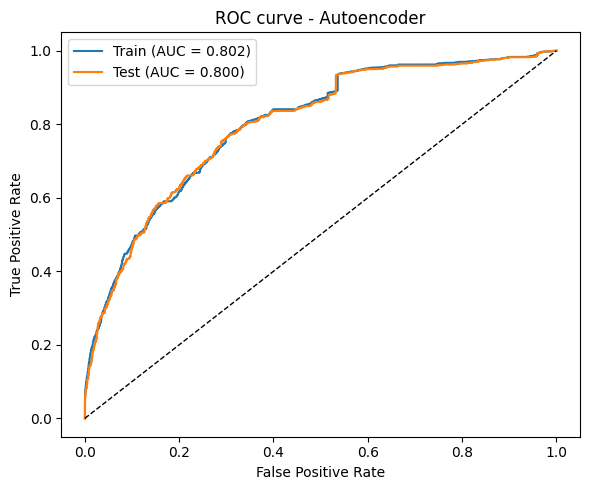

In [27]:
fpr_tr, tpr_tr, _ = roc_curve(y_train, err_train)
fpr_te, tpr_te, _ = roc_curve(y_test,  err_test)

plt.figure(figsize=(6, 5))
plt.plot(fpr_tr, tpr_tr, label=f"Train (AUC = {res.loc['ROC AUC','Training Data']:.3f})")
plt.plot(fpr_te, tpr_te, label=f"Test (AUC = {res.loc['ROC AUC','Test Data']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curve - Autoencoder"); plt.legend(); plt.tight_layout(); plt.show()

**Reconstruction error trên tập test & ngưỡng**

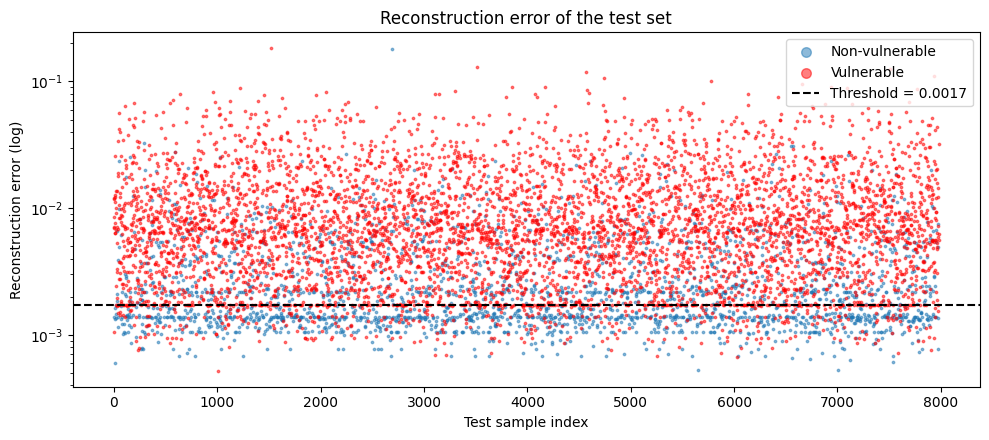

In [28]:
plt.figure(figsize=(10, 4.5))
idx_n = np.where(y_test == 0)[0]; idx_v = np.where(y_test == 1)[0]
plt.scatter(idx_n, err_test[idx_n], s=3, alpha=0.5, label="Non-vulnerable")
plt.scatter(idx_v, err_test[idx_v], s=3, alpha=0.5, color="red", label="Vulnerable")
plt.axhline(threshold, color="k", ls="--", label=f"Threshold = {threshold:.4f}")
plt.yscale("log"); plt.xlabel("Test sample index"); plt.ylabel("Reconstruction error (log)")
plt.title("Reconstruction error of the test set"); plt.legend(markerscale=4)
plt.tight_layout(); plt.show()

**Confusion matrix**

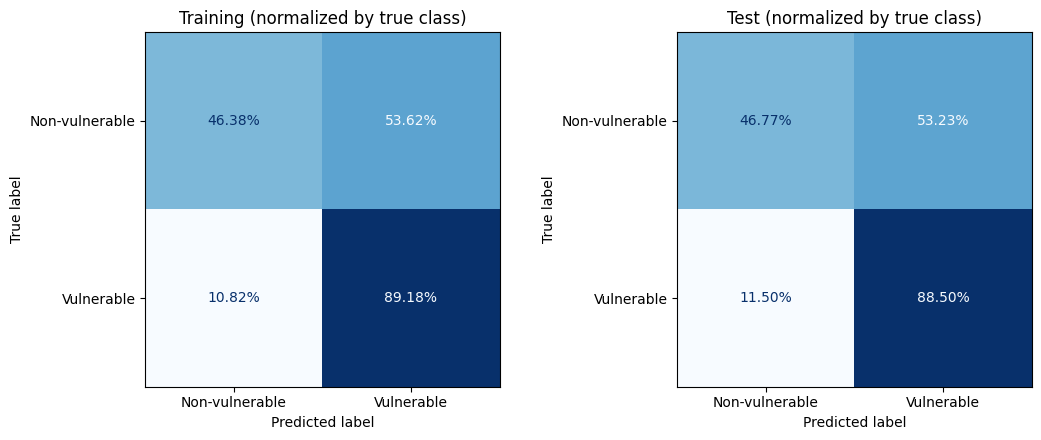

Confusion matrix (số lượng) - Test:
                     Pred Non-vulnerable  Pred Vulnerable
True Non-vulnerable                 1109             1262
True Vulnerable                      645             4965


In [29]:
labels = ["Non-vulnerable", "Vulnerable"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (name, yt, yp) in zip(ax, [("Training", y_train, pred_train), ("Test", y_test, pred_test)]):
    cm = confusion_matrix(yt, yp, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=a, cmap="Blues", values_format=".2%", colorbar=False)
    a.set_title(f"{name} (normalized by true class)")
plt.tight_layout(); plt.show()

print("Confusion matrix (số lượng) - Test:")
print(pd.DataFrame(confusion_matrix(y_test, pred_test), index=[f"True {l}" for l in labels],
                   columns=[f"Pred {l}" for l in labels]))

# **CẢI THIỆN KẾT QUẢ AUTOENCODER**

Hai nguyên nhân chính làm kết quả thấp ở lần chạy đầu:
1. **Ngưỡng chọn theo F1 của lớp Vulnerable** (chiếm 70% dữ liệu) nên mô hình có xu hướng gán nhãn Vulnerable cho hầu hết mẫu → 1262/2371 contract Non-vulnerable bị báo nhầm, kéo thấp Balanced Accuracy.
2. **Autoencoder chưa hội tụ**: 8,537 mẫu / batch 2048 ≈ 5 bước cập nhật mỗi epoch, 20 epochs chỉ ≈ 100 bước; loss vẫn còn giảm ở epoch 20.

**Chọn lại ngưỡng theo Youden's J (cực đại TPR − FPR) trên tập train**

Tương đương cực đại Balanced Accuracy, phù hợp hơn khi dữ liệu lệch nhãn và khi báo cáo bằng Balanced Accuracy / Macro metrics.

In [30]:
from sklearn.metrics import roc_curve, balanced_accuracy_score, precision_recall_fscore_support, roc_auc_score

def youden_threshold(y_true, score):
    fpr, tpr, thr = roc_curve(y_true, score)
    return thr[np.argmax(tpr - fpr)]

def evaluate_at(y_true, score, thr):
    pred = (score > thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    return {"Balanced Accuracy": balanced_accuracy_score(y_true, pred),
            "Macro Precision": p, "Macro Recall": r, "Macro F1": f,
            "ROC AUC": roc_auc_score(y_true, score)}

thr_youden = youden_threshold(y_train, err_train)
print(f"Threshold F1-based    : {threshold:.6f}")
print(f"Threshold Youden's J  : {thr_youden:.6f}")

cmp = pd.DataFrame({
    "Test - ngưỡng F1 (cũ)":   evaluate_at(y_test, err_test, threshold),
    "Test - ngưỡng Youden (mới)": evaluate_at(y_test, err_test, thr_youden),
})
display(cmp.round(4))

Threshold F1-based    : 0.001708
Threshold Youden's J  : 0.002951


,Test - ngưỡng F1 (cũ),Test - ngưỡng Youden (mới)
Balanced Accuracy,0.6764,0.7318
Macro Precision,0.7148,0.7071
Macro Recall,0.6764,0.7318
Macro F1,0.6883,0.7142
ROC AUC,0.7998,0.7998


**Thử nghiệm cấu hình huấn luyện**

Các cấu hình được so sánh bằng **validation set tách từ train** (có cả hai lớp) — *không dùng test để chọn cấu hình* nhằm tránh rò rỉ dữ liệu.
- `A_paper`: cấu hình gốc (batch 2048, 20 epochs, log1p).
- `B_smallbatch`: batch 128, tối đa 150 epochs, EarlyStopping theo val_loss.
- `C_freq`: như B nhưng dùng **tần suất opcode** (chia cho tổng opcode của contract) để giảm ảnh hưởng của kích thước contract.
- `D_wide`: như B nhưng mạng rộng hơn (256→192→128→64→128→192→256).

In [31]:
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

def prep_features(Xtr, Xte, mode):
    if mode == "log":
        ftr, fte = np.log1p(Xtr), np.log1p(Xte)
    elif mode == "freq":
        ftr = np.sqrt(Xtr / np.maximum(Xtr.sum(1, keepdims=True), 1))
        fte = np.sqrt(Xte / np.maximum(Xte.sum(1, keepdims=True), 1))
    sc = MinMaxScaler().fit(ftr)
    return (sc.transform(ftr).astype("float32"),
            np.clip(sc.transform(fte), 0, 1).astype("float32"))

def build_ae(dims, input_dim=256, lr=1e-3):
    inp = keras.Input(shape=(input_dim,))
    x = inp
    for d in dims[:-1]:
        x = layers.Dense(d, activation="tanh")(x)
    z = layers.Dense(dims[-1], activation="tanh", name="bottleneck")(x)
    x = z
    for d in dims[-2::-1]:
        x = layers.Dense(d, activation="tanh")(x)
    out = layers.Dense(input_dim, activation="sigmoid")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="mse")
    return m

def fit_ae(Xn, cfg, verbose=0):
    Xf, Xv = train_test_split(Xn, test_size=0.1, random_state=SEED)
    m = build_ae(cfg["dims"])
    cb = []
    if cfg["early_stop"]:
        cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
    t0 = time.time()
    h = m.fit(Xf, Xf, epochs=cfg["epochs"], batch_size=cfg["batch"],
              validation_data=(Xv, Xv), shuffle=True, callbacks=cb, verbose=verbose)
    return m, h, time.time() - t0

CONFIGS = {
    "A_paper":      dict(feat="log",  dims=(128, 64, 32),     batch=2048, epochs=20,  early_stop=False),
    "B_smallbatch": dict(feat="log",  dims=(128, 64, 32),     batch=128,  epochs=150, early_stop=True),
    "C_freq":       dict(feat="freq", dims=(128, 64, 32),     batch=128,  epochs=150, early_stop=True),
    "D_wide":       dict(feat="log",  dims=(192, 128, 64),    batch=128,  epochs=150, early_stop=True),
}

# Validation nội bộ (có cả 2 lớp), tách từ train
idx_tr, idx_va = train_test_split(np.arange(len(y_train)), test_size=0.2,
                                  stratify=y_train, random_state=SEED)
Xtr_raw, ytr_in = X_train[idx_tr], y_train[idx_tr]
Xva_raw, yva_in = X_train[idx_va], y_train[idx_va]

rows = []
for name, cfg in CONFIGS.items():
    a, b = prep_features(Xtr_raw, Xva_raw, cfg["feat"])
    m, h, tt = fit_ae(a[ytr_in == 0], cfg)
    e_tr = np.mean((a - m.predict(a, batch_size=4096, verbose=0))**2, axis=1)
    e_va = np.mean((b - m.predict(b, batch_size=4096, verbose=0))**2, axis=1)
    thr_ = youden_threshold(ytr_in, e_tr)
    r = evaluate_at(yva_in, e_va, thr_)
    r.update(config=name, epochs_run=len(h.history["loss"]), train_time_s=round(tt, 1))
    rows.append(r)
    print(f"{name}: val AUC={r['ROC AUC']:.4f}  val BalAcc={r['Balanced Accuracy']:.4f}  epochs={r['epochs_run']}")

exp = pd.DataFrame(rows).set_index("config")
display(exp.round(4))
best_name = exp["ROC AUC"].idxmax()
print("Cấu hình tốt nhất trên validation:", best_name)

A_paper: val AUC=0.8021  val BalAcc=0.7351  epochs=20
B_smallbatch: val AUC=0.9236  val BalAcc=0.8504  epochs=150
C_freq: val AUC=0.9022  val BalAcc=0.8450  epochs=150
D_wide: val AUC=0.9267  val BalAcc=0.8524  epochs=150


,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,ROC AUC,epochs_run,train_time_s
config,,,,,,,
A_paper,0.7351,0.7147,0.7351,0.7218,0.8021,20,16.6
B_smallbatch,0.8504,0.8463,0.8504,0.8483,0.9236,150,68.2
C_freq,0.8450,0.8131,0.8450,0.8247,0.9022,150,40.5
D_wide,0.8524,0.8496,0.8524,0.8510,0.9267,150,55.4


Cấu hình tốt nhất trên validation: D_wide


**Huấn luyện lại cấu hình tốt nhất trên toàn bộ train và đánh giá trên test (một lần duy nhất)**

Config: D_wide | threshold = 0.000098 | epochs chạy: 150


,Training Data,Test Data
Balanced Accuracy,0.8624,0.8571
Macro Precision,0.8460,0.8408
Macro Recall,0.8624,0.8571
Macro F1,0.8533,0.8481
ROC AUC,0.9345,0.9248
Time (s),58.1146,3.2572


,Lần 1 (test),Sau cải thiện (test),Bài báo (test)
Balanced Accuracy,0.6764,0.8571,0.7446
Macro Precision,0.7148,0.8408,0.5000
Macro Recall,0.6764,0.8571,0.7446
Macro F1,0.6883,0.8481,0.4874
ROC AUC,0.7998,0.9248,0.8393


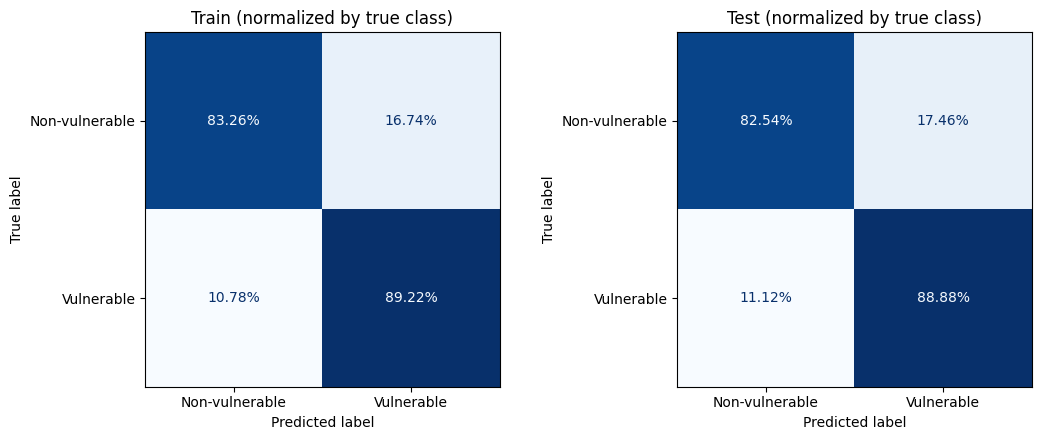

In [32]:
best = CONFIGS[best_name]
a_tr, a_te = prep_features(X_train, X_test, best["feat"])

m_best, h_best, t_fit = fit_ae(a_tr[y_train == 0], best, verbose=0)
e_tr = np.mean((a_tr - m_best.predict(a_tr, batch_size=4096, verbose=0))**2, axis=1)
t0 = time.time()
e_te = np.mean((a_te - m_best.predict(a_te, batch_size=4096, verbose=0))**2, axis=1)
t_inf = time.time() - t0

thr_best = youden_threshold(y_train, e_tr)
final = pd.DataFrame({
    "Training Data": evaluate_at(y_train, e_tr, thr_best),
    "Test Data":     evaluate_at(y_test,  e_te, thr_best),
})
final.loc["Time (s)"] = [t_fit, t_inf]
print(f"Config: {best_name} | threshold = {thr_best:.6f} | epochs chạy: {len(h_best.history['loss'])}")
display(final.round(4))

paper = {"Balanced Accuracy": 0.744587, "Macro Precision": 0.500024,
         "Macro Recall": 0.744587, "Macro F1": 0.487417, "ROC AUC": 0.839342}
compare = pd.DataFrame({
    "Lần 1 (test)":   evaluate_at(y_test, err_test, threshold),
    "Sau cải thiện (test)": final["Test Data"].drop("Time (s)"),
    "Bài báo (test)": pd.Series(paper),
})
display(compare.round(4))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a_, (nm, yt, sc_) in zip(ax, [("Train", y_train, e_tr), ("Test", y_test, e_te)]):
    cm = confusion_matrix(yt, (sc_ > thr_best).astype(int), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=["Non-vulnerable", "Vulnerable"]).plot(
        ax=a_, cmap="Blues", values_format=".2%", colorbar=False)
    a_.set_title(f"{nm} (normalized by true class)")
plt.tight_layout(); plt.show()